# Câu a:
Sử dụng kỹ thuật Silhouette Score và Elbow Method để xác định 
tham số K cho bộ dữ liệu trên. Cho biết K bằng bao nhiêu theo biểu 
đồ; 

In [21]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import underthesea   
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

### Đọc dữ liệu


In [22]:
Path = os.path.join(os.getcwd(), "Data")

def read_file(filename):
    filename = os.path.join(Path, filename)
    with open(filename, 'r', encoding="utf-16") as f:
        data = f.read()
    return data

def natural_key(name):
    m = re.match(r"(.+?)_ \((\d+)\)\.txt$", name)
    return (m.group(1), int(m.group(2))) if m else (name, 0)

file_names = sorted([f for f in os.listdir(Path) if f.endswith(".txt")], key=natural_key)

Raw_Data = {}      
errors = []
for name in file_names:
    try:
        Raw_Data[name] = read_file(name)
    except Exception as e:
        errors.append((name, str(e)))


In [23]:
StopWords_File = os.path.join(os.getcwd(), "vietnamese-stopwords.txt")

if os.path.exists(StopWords_File):
    with open(StopWords_File, "r", encoding="utf-8") as f:
        List_StopWords = set(w.strip().lower().replace(" ", "_")
                             for w in f.read().split("\n") if w.strip())
else:
    List_StopWords = set()

In [24]:
def Text_Preprocessing(doc):
    text_pre = doc.lower()                                   # Chuyển chữ thường

    text_pre = underthesea.word_tokenize(text_pre, format="text")   # Tách từ tiếng Việt
    text_pre = underthesea.text_normalize(text_pre)                 # Chuẩn hóa dấu tiếng Việt

    text_pre = text_pre.replace(u'�', '')               # Xóa ký tự lỗi
    text_pre = re.sub(r'http\S+', '', text_pre)              # Xóa URL có http
    text_pre = re.sub(r'www\S+', '', text_pre)               # Xóa URL có www
    text_pre = re.sub(r"\S*@\S*\s?", " ", text_pre)          # Xóa email
    text_pre = re.sub(r'[^\w\s]', ' ', text_pre)             # Xóa dấu câu, ký tự đặc biệt (giữ dấu _)
    text_pre = re.sub(r"\S*\d\S*", " ", text_pre)            # Xóa số và từ dính số
    text_pre = re.sub(r'\s+', ' ', text_pre).strip()         # Xóa khoảng trắng thừa, xuống dòng

    # Loại bỏ stopwords
    if List_StopWords:
        text_pre = " ".join(w for w in text_pre.split() if w not in List_StopWords)

    return text_pre

### tiền xử lý toàn bộ dữ liệu

In [25]:
Data = {}         
for name, content in Raw_Data.items():
    Data[name] = Text_Preprocessing(content)


empty_docs = [n for n, t in Data.items() if not t.strip()]
for n in empty_docs:
    del Data[n]
print(f"Số văn bản sau tiền xử lý: {len(Data)}")

Số văn bản sau tiền xử lý: 475


### TF-IDF

In [26]:
file_list = list(Data.keys())        
corpus    = list(Data.values())      

tfidf_vectorizer = TfidfVectorizer(max_df=0.5, min_df=2)
X = tfidf_vectorizer.fit_transform(corpus)
terms = tfidf_vectorizer.get_feature_names_out()
print("TF-IDF:", X.shape)

TF-IDF: (475, 4836)


## TÍNH WCSS (ELBOW) VÀ SILHOUETTE SCORE


In [27]:
K_max = 11                 
K_values = range(2, K_max)
wcss = []
silhouette_scores = []

for i in K_values:
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)
    score = silhouette_score(X, kmeans.labels_)
    silhouette_scores.append(score)
    print(f"K = {i:2d} | WCSS = {kmeans.inertia_:8.2f} | Silhouette = {score:.4f}")

K =  2 | WCSS =   448.17 | Silhouette = 0.0182
K =  3 | WCSS =   439.33 | Silhouette = 0.0269
K =  4 | WCSS =   431.07 | Silhouette = 0.0323
K =  5 | WCSS =   424.97 | Silhouette = 0.0370
K =  6 | WCSS =   420.49 | Silhouette = 0.0350
K =  7 | WCSS =   417.78 | Silhouette = 0.0294
K =  8 | WCSS =   415.59 | Silhouette = 0.0314
K =  9 | WCSS =   412.35 | Silhouette = 0.0302
K = 10 | WCSS =   409.60 | Silhouette = 0.0280


## VẼ BIỂU ĐỒ

C:\Users\Admin\AppData\Local\Temp\ipykernel_4160\75438405.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[0].legend(); ax[0].grid(True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_4160\75438405.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend(); ax[1].grid(True)


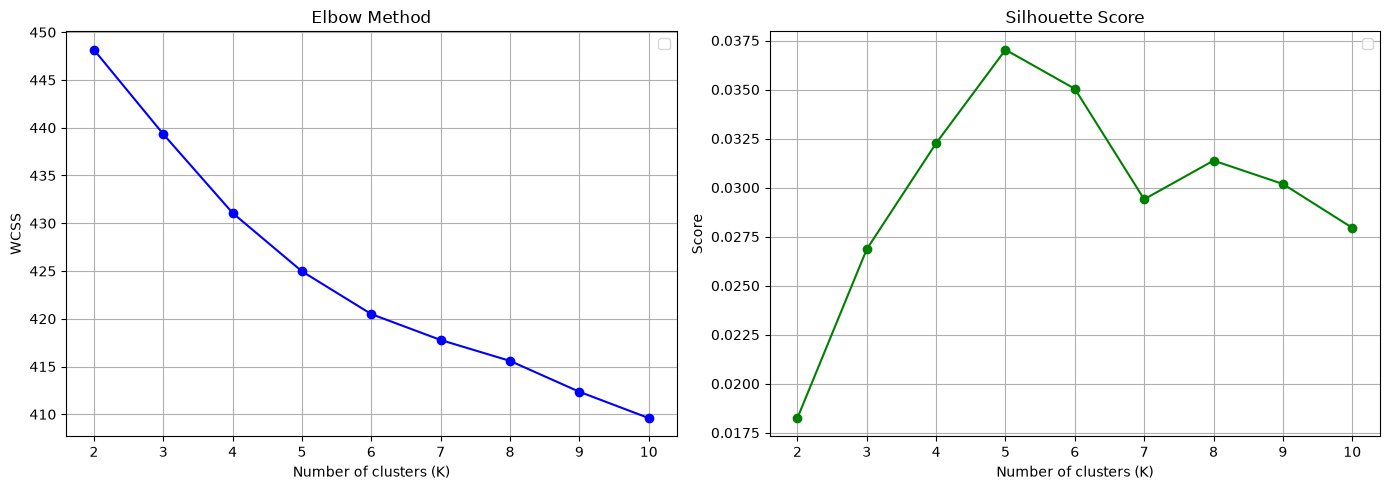

In [28]:

K_silhouette = list(K_values)[int(np.argmax(silhouette_scores))]

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(K_values, wcss, marker='o', color='b')
ax[0].set_title('Elbow Method')
ax[0].set_xlabel('Number of clusters (K)')
ax[0].set_ylabel('WCSS')
ax[0].legend(); ax[0].grid(True)

ax[1].plot(K_values, silhouette_scores, marker='o', color='g')
ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('Number of clusters (K)')
ax[1].set_ylabel('Score')
ax[1].legend(); ax[1].grid(True)

plt.tight_layout()
plt.show()

- Elbow Method     :  K = 5
- Silhouette Score :  K = 5 (score = 0.0370)
- KẾT LUẬN: Chọn K = 5